In [1]:
import numpy as np
import os
import matplotlib.pyplot as plt

import astropy.units as u
import astropy.constants as const

import json
import h5py

In [2]:
from synch_emission_functions import f_p_0, f_e_0, mp, me, c, ep_ratio, synch_kernel, crit_freq, ekin

In [3]:
# load the bowshock config
bowshock_config = json.load(open("../../config/bowshock_config.json", "r"))["config"]

In [4]:
# energy parameters
pp_arr = np.logspace(0, 4, 200)
print(
    f"Minimum & maximum of normalised momentum (protons): {(pp_arr.min() * mp * c**2).to(u.GeV):.5f}, {(pp_arr.max() * mp * c**2).to(u.GeV):.5f}"
)

pe_arr = np.logspace(2, 7, 200)
print(
    f"Minimum & maximum of normalised momentum (electrons): {(pe_arr.min() * me * c**2).to(u.GeV):.5f}, {(pe_arr.max() * me * c**2).to(u.GeV):.5f}"
)
Kep, pp0, pe0 = (
    ep_ratio()
)  # get the normalisation for the electron spectrum based on the proton spectrum at 10 GeV, and the corresponding momenta

Minimum & maximum of normalised momentum (protons): 0.93827 GeV, 9382.72088 GeV
Minimum & maximum of normalised momentum (electrons): 0.05110 GeV, 5109.98950 GeV
ep ratio parameters: 0.01, 10.658, 19569.512


In [5]:
dens_val = 1e-25 * (u.g / u.cm**3)
r_pos = 5 * u.pc
vel_val = 100 * u.km/u.s

alpha_inj_val = 4.2
synch_freq_factor = 0.29  # synch_freq = synch_freq_factor * nu_crit

In [6]:
def synch_coeff(Blos):
    """Coefficient in front of synchrotron integral."""
    return (np.sqrt(3) * const.e.gauss.value**3 * Blos.to_value(u.G)) / (me.value * c.value**2)

In [7]:
# synchrotron kernel + electron spectra plot at fixed synchrotron frequency
# nu = 0.29 * nu_crit
sim_name = "ISM-v40-MDiff"
Blos_grid = np.logspace(-2, 1, 100) * u.uG

EELE, BLOS = np.meshgrid(pe_arr, Blos_grid)

# Calculate electron spectrum for each magnetic field value
f_e_2d = np.zeros_like(EELE)
for imag, mag_val in enumerate(Blos_grid):
    fe0 = f_e_0(
        alpha_inj_val,
        pe_arr,
        dens_val,
        mag_val,
        Tstar=1e4 * u.K,
        vel=vel_val,
        pmax=bowshock_config[sim_name]["pmax_electr"],
        vstar=bowshock_config[sim_name]["vstar"] * (u.km / u.s),
        r_pos=r_pos,
    )

    f_e = Kep * f_p_0(
        alpha_inj_val,
        pp0,
        dens_val,
        vel_val,
        pmax=bowshock_config[sim_name]["pmax_prot"],
        vstar=bowshock_config[sim_name]["vstar"] * (u.km/u.s)
    ) / f_e_0(
        alpha_inj_val,
        pe0,
        dens_val,
        mag_val,
        Tstar=1e4 * u.K,
        vel=vel_val,
        pmax=bowshock_config[sim_name]["pmax_electr"],
        vstar=bowshock_config[sim_name]["vstar"] * (u.km / u.s),
        r_pos=r_pos,
    ) * fe0
    
    f_e_2d[imag, :] = f_e

# Calculate critical frequency
crit_freq_grid = crit_freq(BLOS, EELE)

# Calculate synchrotron frequency at 0.29 * nu_crit
synch_freq = synch_freq_factor * crit_freq_grid
synch_kern = synch_coeff(BLOS) * synch_kernel((synch_freq / crit_freq_grid).value)

# Combine synchrotron kernel with electron spectrum
synch_kern_plus_spectra = synch_kern * f_e_2d

# normalise to maximum
synch_kern_plus_spectra /= np.max(synch_kern_plus_spectra)



In [ ]:
fig, ax = plt.subplots(figsize=(8, 6))

ax.pcolormesh(
    BLOS.value,
    (EELE * (me * c**2)).to(u.GeV).value,
    synch_kern_plus_spectra,
    shading="auto",
    norm=plt.matplotlib.colors.LogNorm(vmin=1e-5, vmax=1, clip=True),
    cmap="plasma",
)
cbar = plt.colorbar(ax.collections[0], ax=ax)
cbar.set_label(r"$f_e(p_e) \, F(\nu / \nu_c)$ [a.u.]", fontsize=16)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel(r"$B_{\perp}$ [$\mu$G]", fontsize=16)
ax.set_ylabel(r"$p_e$ [GeV/c]", fontsize=16)

ax.set_title(r"Synchrotron Kernel + Electron Spectra, $\nu$ = $0.29 \, \nu_c$", fontsize=18)

fig.tight_layout()
plt.show()

fig.savefig("synchrotron_kernel_electron_spectra_fixed_freq.png", dpi=300, bbox_inches="tight")

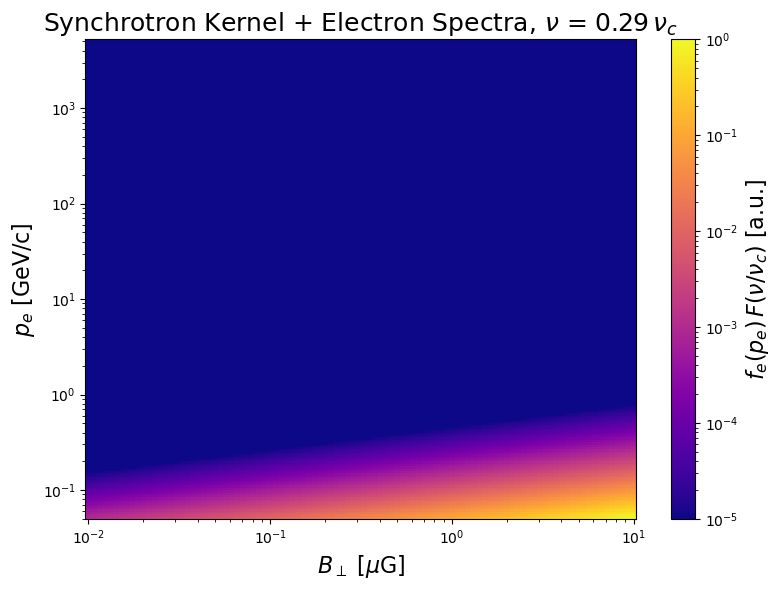

In [11]:
fig, ax = plt.subplots(figsize=(8, 6))

ax.pcolormesh(
    BLOS.value,
    (EELE * (me * c**2)).to(u.GeV).value,
    synch_kern_plus_spectra,
    shading="auto",
    norm=plt.matplotlib.colors.LogNorm(vmin=1e-5, vmax=1, clip=True),
    cmap="plasma",
)
cbar = plt.colorbar(ax.collections[0], ax=ax)
cbar.set_label(r"$f_e(p_e) \, F(\nu / \nu_c)$ [a.u.]", fontsize=16)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel(r"$B_{\perp}$ [$\mu$G]", fontsize=16)
ax.set_ylabel(r"$p_e$ [GeV/c]", fontsize=16)

ax.set_title(r"Synchrotron Kernel + Electron Spectra, $\nu$ = $0.29 \, \nu_c$", fontsize=18)

fig.tight_layout()
plt.show()

fig.savefig("synchrotron_kernel_electron_spectra_fixed_freq.png", dpi=300, bbox_inches="tight")

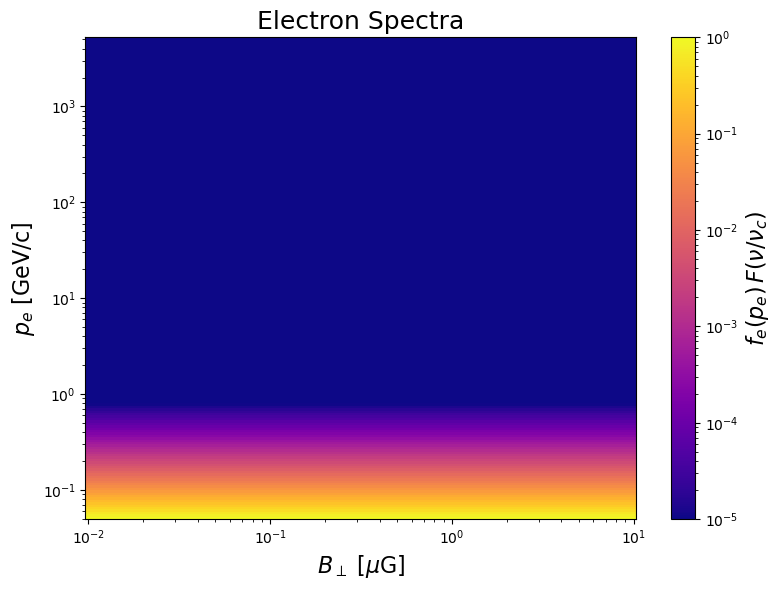

In [12]:
fig, ax = plt.subplots(figsize=(8, 6))

ax.pcolormesh(
    BLOS.value,
    (EELE * (me * c**2)).to(u.GeV).value,
    f_e_2d / np.max(f_e_2d),
    shading="auto",
    norm=plt.matplotlib.colors.LogNorm(vmin=1e-5, vmax=1, clip=True),
    cmap="plasma",
)
cbar = plt.colorbar(ax.collections[0], ax=ax)
cbar.set_label(r"$f_e(p_e) \, F(\nu / \nu_c)$", fontsize=16)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel(r"$B_{\perp}$ [$\mu$G]", fontsize=16)
ax.set_ylabel(r"$p_e$ [GeV/c]", fontsize=16)

ax.set_title(r"Electron Spectra", fontsize=18)

fig.tight_layout()
plt.show()

fig.savefig("electron_spectra_fixed_freq.png", dpi=300, bbox_inches="tight")

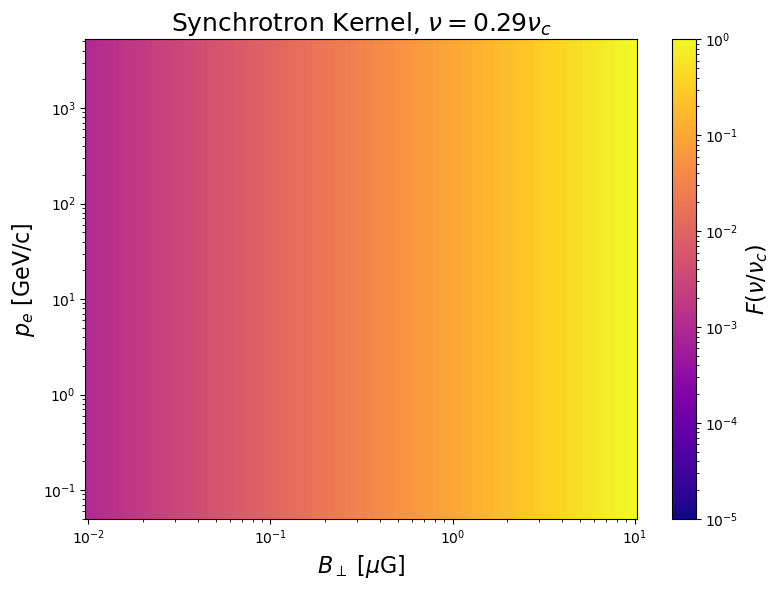

In [13]:
fig, ax = plt.subplots(figsize=(8, 6))

ax.pcolormesh(
    BLOS.value,
    (EELE * (me * c**2)).to(u.GeV).value,
    synch_kern / np.max(synch_kern),
    shading="auto",
    norm=plt.matplotlib.colors.LogNorm(vmin=1e-5, vmax=1, clip=True),
    cmap="plasma",
)
cbar = plt.colorbar(ax.collections[0], ax=ax)
cbar.set_label(r"$F(\nu / \nu_c)$", fontsize=16)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel(r"$B_{\perp}$ [$\mu$G]", fontsize=16)
ax.set_ylabel(r"$p_e$ [GeV/c]", fontsize=16)

ax.set_title(r"Synchrotron Kernel, $\nu = 0.29 \nu_c$", fontsize=18)

fig.tight_layout()
plt.show()

fig.savefig("synchrotron_kernel_fixed_freq.png", dpi=300, bbox_inches="tight")